image preprocessing

In [ ]:
import os

import numpy as np
from skimage.color import rgb2gray
from skimage.io import imread
from skimage.transform import resize

input_dir = "Dateset/final_dataset_clean"
categories = ["glioma", "meningioma", "notumor", "pituitary"]

data = []
labels = []

for categorie_idx, categorie in enumerate(categories):
    for file in os.listdir(os.path.join(input_dir, categorie)):
        img_path = os.path.join(input_dir, categorie, file)
        img = imread(img_path)
        img = resize(img, (32, 32))
        if img.ndim > 2:
            img = rgb2gray(img)
        data.append(img.flatten())
        labels.append(categorie_idx)

data = np.asanyarray(data)
labels = np.asanyarray(labels)

séparation des données

In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    data, labels, test_size=0.2, shuffle=True, stratify=labels
)

Optimisation des hyperparamètres du modèle SVM par Grid Search

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

classifier = SVC()

parameters = [{"gamma": [0.01, 0.001, 0.0001], "C": [1, 10, 100, 1000]}]

grid_search = GridSearchCV(classifier, parameters)

grid_search.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'C': [1, 10, ...], 'gamma': [0.01, 0.001, ...]}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with h

Évaluation et visualisation des performances du modèle SVM :
    Génération du classification report (précision, rappel, F1-score).
    Affichage de la matrice de confusion et de sa version normalisée.
    Analyse des meilleurs hyperparamètres trouvés par Grid Search.
    visualiser des performances avec les courbes ROC et l'AUC.

MODEL PERFORMANCE
Test Accuracy: 88.91%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.8466    0.8905    0.8680       347
  meningioma     0.8196    0.7969    0.8081       325
     notumor     0.9274    0.8877    0.9071       374
   pituitary     0.9588    0.9790    0.9688       333

    accuracy                         0.8891      1379
   macro avg     0.8881    0.8885    0.8880      1379
weighted avg     0.8892    0.8891    0.8888      1379



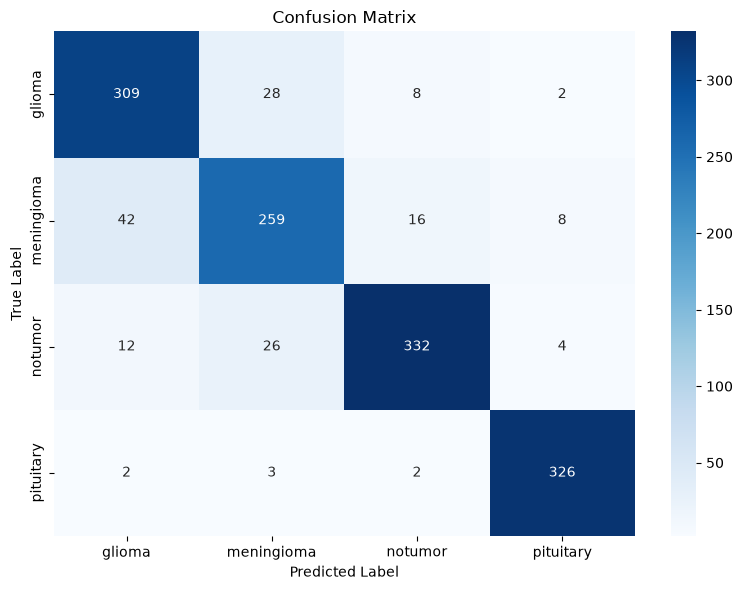

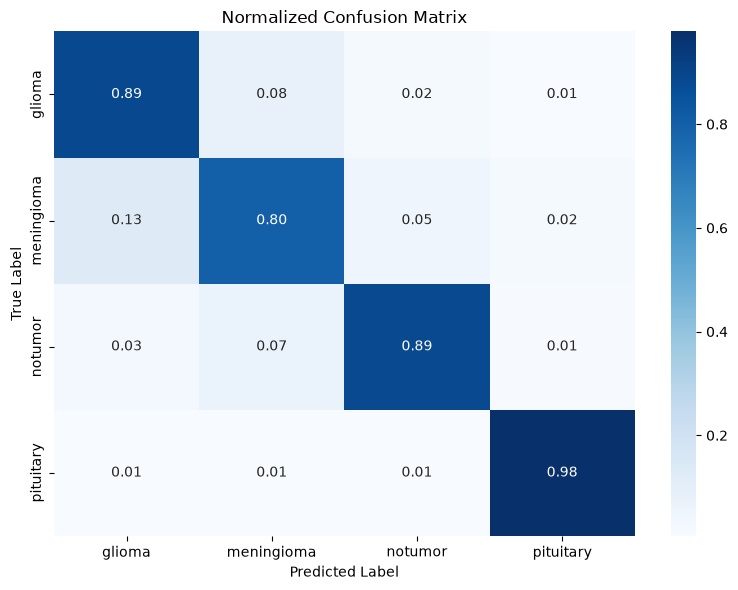


BEST HYPERPARAMETERS
{'C': 1000, 'gamma': 0.01}
Best cross-validation score: 88.66%


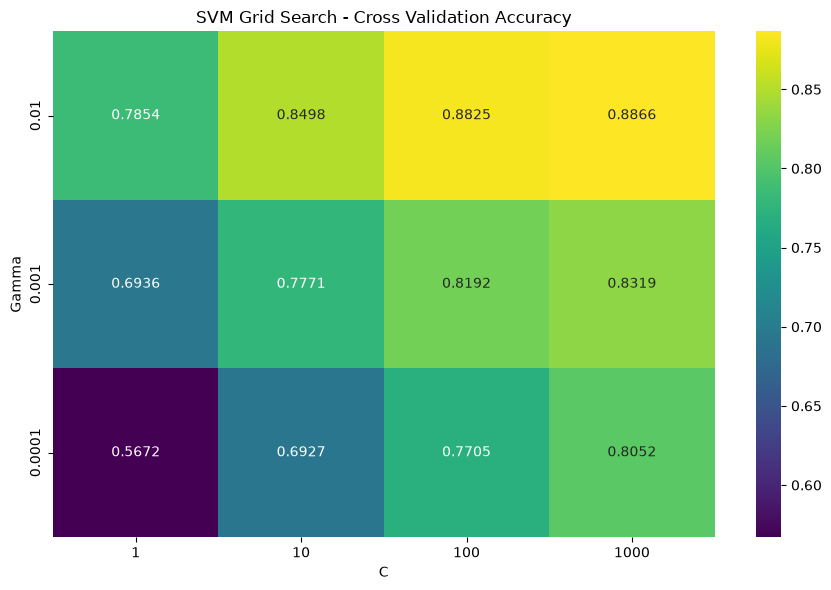

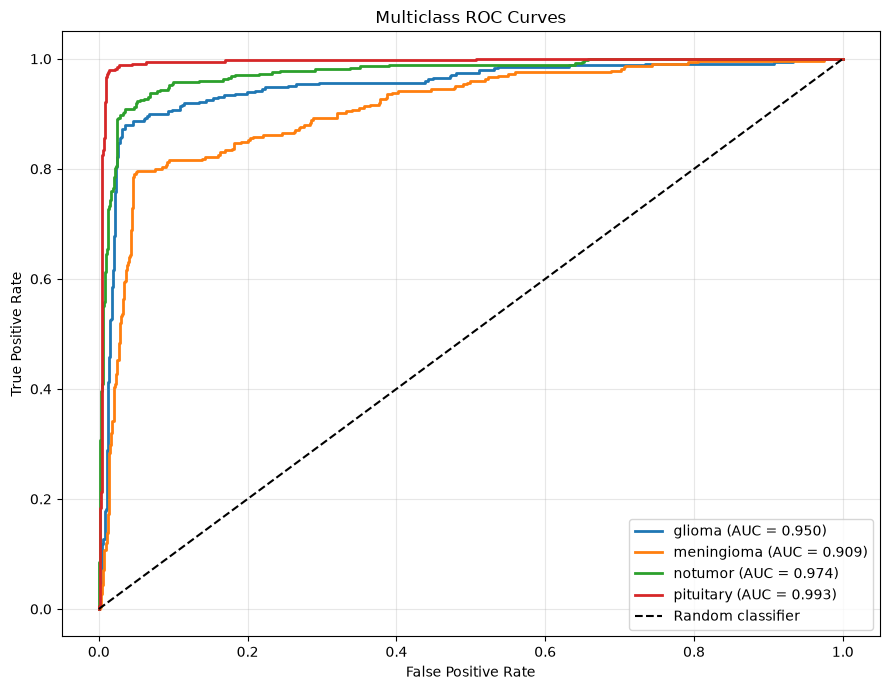

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

best_estimator = grid_search.best_estimator_

y_prediction = best_estimator.predict(x_test)

score = accuracy_score(y_prediction, y_test)

class_names = categories

# Accuracy

accuracy = accuracy_score(y_test, y_prediction)

print("=" * 60)
print("MODEL PERFORMANCE")
print("=" * 60)
print(f"Test Accuracy: {accuracy * 100:.2f}%")


# Detailed Classification Report

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

report = classification_report(y_test, y_prediction, target_names=class_names, digits=4)

print(report)


# Confusion Matrix

cm = confusion_matrix(y_test, y_prediction)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


# Normalized Confusion Matrix

cm_normalized = confusion_matrix(y_test, y_prediction, normalize="true")

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix")
plt.tight_layout()
plt.show()


# Best Hyperparameters

print("\n" + "=" * 60)
print("BEST HYPERPARAMETERS")
print("=" * 60)

print(grid_search.best_params_)
print(f"Best cross-validation score: {grid_search.best_score_ * 100:.2f}%")


# 6. GridSearchCV Results

results = grid_search.cv_results_

C_values = parameters[0]["C"]
gamma_values = parameters[0]["gamma"]

scores = np.zeros((len(gamma_values), len(C_values)))

for i, gamma in enumerate(gamma_values):
    for j, C in enumerate(C_values):
        for k, params in enumerate(results["params"]):
            if params["C"] == C and params["gamma"] == gamma:
                scores[i, j] = results["mean_test_score"][k]


plt.figure(figsize=(9, 6))

sns.heatmap(
    scores,
    annot=True,
    fmt=".4f",
    cmap="viridis",
    xticklabels=C_values,
    yticklabels=gamma_values,
)

plt.xlabel("C")
plt.ylabel("Gamma")
plt.title("SVM Grid Search - Cross Validation Accuracy")
plt.tight_layout()
plt.show()


from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

# Convert labels to one-hot representation
y_test_bin = label_binarize(y_test, classes=np.arange(len(categories)))

# Get SVM decision scores
y_score = best_estimator.decision_function(x_test)

plt.figure(figsize=(9, 7))

for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])

    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, linewidth=2, label=f"{class_name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
